# Assignment 3: Skip-gram with Negative Sampling (Word2Vec)

**Objective:** Implement Word2Vec **SGNS** in Python. 

## The idea in one paragraph

Skip-gram says: *a word should predict the words that sit next to it.* Doing that with a softmax over the whole vocabulary is slow. **Negative sampling** turns it into a small yes/no problem:

- **Yes:** this neighbor really appeared next to the center word
- **No:** this random word did *not*

We push the real neighbor’s vector toward the center word, and push the random words away. That is the whole algorithm.

## Plan

1. Tokenize text and give every word an integer id
2. Build skip-gram `(center, context)` pairs from a window
3. Draw negative samples from `P(w) ∝ count(w)^0.75`
4. SGD on logistic regression (`sigmoid` + binary cross-entropy)
5. Look up nearest neighbors with cosine similarity


In [23]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output, display


def sigmoid(x):
    """Return 1 / (1 + exp(-x)), clipped so exp does not overflow."""
    x = np.clip(x, -20.0, 20.0)
    return 1.0 / (1.0 + np.exp(-x))


print("sigmoid(0)  =", sigmoid(0.0))
print("sigmoid(5)  =", round(float(sigmoid(5.0)), 3))
print("sigmoid(-5) =", round(float(sigmoid(-5.0)), 3))


sigmoid(0)  = 0.5
sigmoid(5)  = 0.993
sigmoid(-5) = 0.007


## 1. Tokens and vocabulary

Turn raw text into a list of words, then map each word to an id. Counts are kept because negative sampling draws words in proportion to frequency.

In [24]:
def tokenize(text):
    """Lowercase `text` and return alphabetic word tokens."""
    return re.findall(r"[a-z]+", text.lower())


def build_vocab(tokens, min_count=1):
    """Build word-id maps and a count vector from a token list.

    Parameters
    ----------
    tokens : list of str
        Tokenized corpus.
    min_count : int
        Drop words that occur fewer than this many times.

    Returns
    -------
    word2id : dict[str, int]
    id2word : dict[int, str]
    counts : ndarray of shape (vocab_size,)
        Raw unigram counts, aligned with ids.
    """
    counter = Counter(tokens)
    words = [w for w, c in counter.most_common() if c >= min_count]
    word2id = {w: i for i, w in enumerate(words)}
    id2word = {i: w for w, i in word2id.items()}
    counts = np.array([counter[w] for w in words], dtype=np.float64)
    return word2id, id2word, counts


## 2. Skip-gram pairs

For a center word at position `i`, every word in `[i - window, i + window]` (except itself) is a **positive** context.

Example with window = 1:

`the king rules` → `(the, king)`, `(king, the)`, `(king, rules)`, `(rules, king)`

In [25]:
def skipgram_pairs(token_ids, window):
    """Build (center, context) id pairs with a symmetric context window.

    For the sequence [a, b, c] and window=1 the pairs are
    (a, b), (b, a), (b, c), (c, b).
    """
    pairs = []
    n = len(token_ids)
    for i, center in enumerate(token_ids):
        left = max(0, i - window)
        right = min(n, i + window + 1)
        for j in range(left, right):
            if j != i:
                pairs.append((center, token_ids[j]))
    return pairs


demo_words = ["the", "king", "rules"]
demo_ids = [0, 1, 2]
print("words:", demo_words)
print("pairs:", [(demo_words[c], demo_words[o]) for c, o in skipgram_pairs(demo_ids, window=1)])


words: ['the', 'king', 'rules']
pairs: [('the', 'king'), ('king', 'the'), ('king', 'rules'), ('rules', 'king')]


## 3. Negative samples

Instead of comparing against every word in the vocab, we draw `k` random “fake” neighbors.

Frequent words are still more likely, but rare words get a slightly bigger chance than raw frequency would give them.

In [26]:
def noise_distribution(counts, power=0.75):
    """Return P(w) proportional to count(w)^power (Mikolov et al.).

    The 0.75 exponent makes rare words a bit more likely to be drawn
    as negatives than a raw unigram would.
    """
    probs = np.power(counts, power)
    probs /= probs.sum()
    return probs


def sample_negatives(context_id, k, noise_probs, rng):
    """Draw `k` unique negative word ids, excluding the true context."""
    vocab_size = len(noise_probs)
    k = min(k, vocab_size - 1)
    negs = []
    seen = {context_id}
    while len(negs) < k:
        word_id = int(rng.choice(vocab_size, p=noise_probs))
        if word_id not in seen:
            seen.add(word_id)
            negs.append(word_id)
    return negs


## 4. The model (two embedding tables)

- `W_in[center]` — vector of the **center** word (this is the embedding we keep)
- `W_out[context]` — vector of a **context** (or negative) word

Score of a pair = dot product. Probability it is a real neighbor = `sigmoid(score)`.

One training step is logistic regression on **1 positive + k negatives**:

- label `1` for the true context → we want `sigmoid(dot)` close to 1
- label `0` for each negative → we want `sigmoid(dot)` close to 0

Gradient of that loss w.r.t. the score is simply `sigmoid(score) - label`. Then SGD updates both tables.

In [27]:
class SkipGramNS:
    """Skip-gram Word2Vec trained with negative sampling.

    Each training step is logistic regression on 1 + k examples:

    * label 1 — the true (center, context) pair
    * label 0 — k randomly drawn (center, negative) pairs

    The vectors we usually keep afterwards are the center rows `W_in`.
    """

    def __init__(self, vocab_size, dim=50, lr=0.05, seed=0):
        """Initialize small random center and context embeddings.

        Parameters
        ----------
        vocab_size : int
            Number of distinct words.
        dim : int
            Embedding dimension.
        lr : float
            SGD learning rate.
        seed : int
            RNG seed for reproducible init.
        """
        rng = np.random.RandomState(seed)
        scale = 0.5 / dim
        self.W_in = rng.uniform(-scale, scale, size=(vocab_size, dim))
        self.W_out = rng.uniform(-scale, scale, size=(vocab_size, dim))
        self.lr = lr
        self.vocab_size = vocab_size

    def train_example(self, center, targets, labels):
        """One SGD step for a center word vs. one positive and k negatives.

        Parameters
        ----------
        center : int
            Center-word id.
        targets : ndarray of shape (1 + k,)
            True context id followed by negative ids.
        labels : ndarray of shape (1 + k,)
            1.0 for the true context, 0.0 for negatives.

        Returns
        -------
        float
            Binary cross-entropy loss for this example.
        """
        h = self.W_in[center].copy()
        v = self.W_out[targets]
        scores = v @ h
        preds = sigmoid(scores)
        error = preds - labels  # dL/d(score)

        self.W_in[center] -= self.lr * (error @ v)
        self.W_out[targets] -= self.lr * np.outer(error, h)

        eps = 1e-12
        return float(
            -np.sum(
                labels * np.log(preds + eps)
                + (1.0 - labels) * np.log(1.0 - preds + eps)
            )
        )

    def most_similar(self, word, word2id, id2word, topn=5):
        """Return the `topn` nearest words by cosine similarity of `W_in`."""
        if word not in word2id:
            return []
        idx = word2id[word]
        norms = np.linalg.norm(self.W_in, axis=1, keepdims=True)
        unit = self.W_in / (norms + 1e-12)
        sims = unit @ unit[idx]
        sims[idx] = -np.inf
        ranked = np.argsort(-sims)[:topn]
        return [(id2word[i], float(sims[i])) for i in ranked]


In [28]:
def train(model, pairs, noise_probs, k, epochs, rng, verbose=True, on_epoch=None):
    """Shuffle pairs each epoch and run SGD with `k` negatives per pair.

    Parameters
    ----------
    on_epoch : callable or None
        If given, called as `on_epoch(epoch, mean_loss, history, model)`
        after every epoch (use this to redraw a learning plot).

    Returns
    -------
    list of float
        Mean loss per epoch.
    """
    history = []
    pairs = list(pairs)
    for epoch in range(epochs):
        rng.shuffle(pairs)
        total = 0.0
        for center, context in pairs:
            negs = sample_negatives(context, k, noise_probs, rng)
            labels = np.array([1.0] + [0.0] * len(negs))
            targets = np.array([context] + negs)
            total += model.train_example(center, targets, labels)
        mean_loss = total / max(len(pairs), 1)
        history.append(mean_loss)
        if on_epoch is not None:
            on_epoch(epoch, mean_loss, history, model)
        elif verbose and ((epoch + 1) % 10 == 0 or epoch == 0):
            print("epoch {:3d}  loss {:.4f}".format(epoch + 1, mean_loss))
    return history


## 5. Train on a tiny corpus

The corpus is small on purpose: royalty sentences vs pet sentences. After each epoch the cell redraws two plots so you can see learning happen:

- **Left:** training loss should fall
- **Right:** word vectors (PCA to 2D) should start to cluster — royalty words together, pet words together

In [29]:
TOY_CORPUS = """
the king rules the kingdom
the queen rules the kingdom
the king and the queen live in the palace
a man is a king
a woman is a queen
the man lives in the house
the woman lives in the house
cats drink milk
dogs chew bones
a cat is a pet
a dog is a pet
cats and dogs live in the house
the prince is a young king
the princess is a young queen
"""

WINDOW = 2
DIM = 30
K_NEG = 5
LR = 0.05
EPOCHS = 80
SEED = 0

tokens = tokenize(TOY_CORPUS)
word2id, id2word, counts = build_vocab(tokens)
token_ids = [word2id[t] for t in tokens]
pairs = skipgram_pairs(token_ids, window=WINDOW)

print("vocab size     :", len(word2id))
print("tokens         :", len(tokens))
print("training pairs :", len(pairs))
print("example pairs  :", [(id2word[c], id2word[o]) for c, o in pairs[:6]])


vocab size     : 27
tokens         : 76
training pairs : 298
example pairs  : [('the', 'king'), ('the', 'rules'), ('king', 'the'), ('king', 'rules'), ('king', 'the'), ('rules', 'the')]


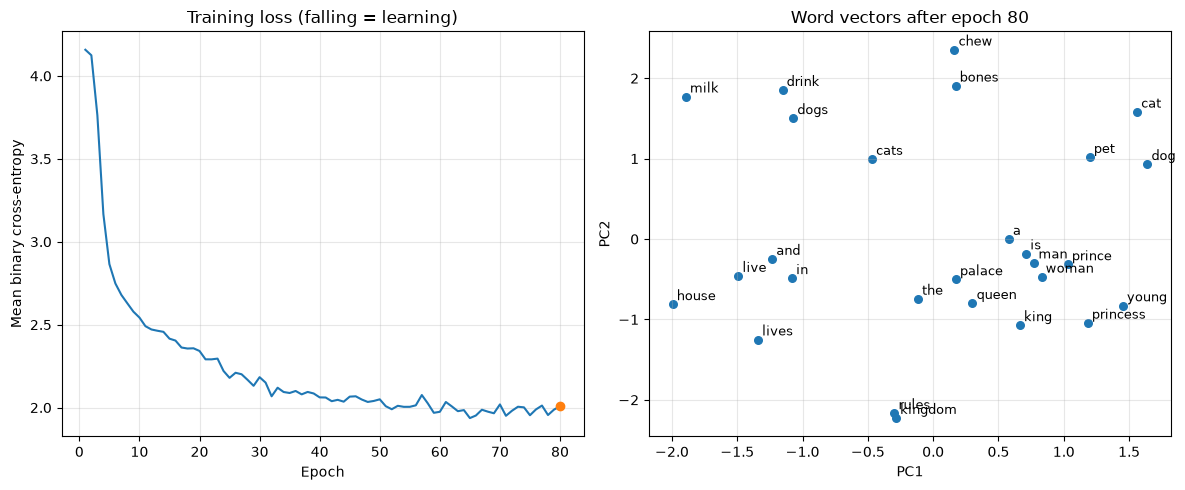

epoch  80  loss 2.0082  (started at 4.1577)


In [30]:
def project_2d(W):
    """Project embedding rows to 2D with PCA (NumPy only)."""
    centered = W - W.mean(axis=0, keepdims=True)
    if W.shape[1] < 2:
        pad = np.zeros((W.shape[0], 2))
        pad[:, : W.shape[1]] = centered
        return pad
    cov = np.cov(centered, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    return centered @ eigvecs[:, np.argsort(eigvals)[-2:]]


def show_learning(epoch, mean_loss, history, model):
    """Redraw loss and word-vector plots after every epoch."""
    clear_output(wait=True)
    fig, (ax_loss, ax_emb) = plt.subplots(1, 2, figsize=(12, 5))

    epochs_x = list(range(1, len(history) + 1))
    ax_loss.plot(epochs_x, history, color="C0")
    ax_loss.scatter([epoch + 1], [mean_loss], color="C1", zorder=3)
    ax_loss.set_title("Training loss (falling = learning)")
    ax_loss.set_xlabel("Epoch")
    ax_loss.set_ylabel("Mean binary cross-entropy")
    ax_loss.grid(True, alpha=0.3)

    xy = project_2d(model.W_in)
    ax_emb.scatter(xy[:, 0], xy[:, 1], s=30, color="C0")
    for i, (x, y) in enumerate(xy):
        ax_emb.annotate(
            id2word[i],
            (x, y),
            fontsize=9,
            xytext=(3, 3),
            textcoords="offset points",
        )
    ax_emb.set_title("Word vectors after epoch {}".format(epoch + 1))
    ax_emb.set_xlabel("PC1")
    ax_emb.set_ylabel("PC2")
    ax_emb.grid(True, alpha=0.3)

    fig.tight_layout()
    display(fig)
    plt.close(fig)
    print(
        "epoch {:3d}  loss {:.4f}  (started at {:.4f})".format(
            epoch + 1, mean_loss, history[0]
        )
    )


rng = np.random.RandomState(SEED)
model = SkipGramNS(vocab_size=len(word2id), dim=DIM, lr=LR, seed=SEED)
history = train(
    model,
    pairs,
    noise_distribution(counts),
    k=K_NEG,
    epochs=EPOCHS,
    rng=rng,
    on_epoch=show_learning,
)



## 6. Nearest neighbors

Cosine similarity on the center embeddings `W_in`. On this toy corpus the numbers are noisy, but related words should rank above unrelated ones.

In [31]:
for query in ("king", "queen", "cat", "dog", "house"):
    neighbors = model.most_similar(query, word2id, id2word, topn=5)
    pretty = ", ".join("{0} ({1:.2f})".format(w, s) for w, s in neighbors)
    print("{0:8s} -> {1}".format(query, pretty))


king     -> queen (0.64), princess (0.52), kingdom (0.50), prince (0.50), rules (0.50)
queen    -> king (0.64), palace (0.64), lives (0.52), prince (0.49), the (0.48)
cat      -> chew (0.77), dog (0.76), pet (0.70), bones (0.62), young (0.58)
dog      -> cat (0.76), princess (0.66), young (0.64), a (0.63), bones (0.62)
house    -> lives (0.83), milk (0.56), live (0.56), palace (0.48), rules (0.38)


## 7. Self-check

Pair building, sigmoid, and “loss goes down” — the smallest checks that fail if the algorithm is broken.

In [32]:
assert skipgram_pairs([0, 1, 2], window=1) == [(0, 1), (1, 0), (1, 2), (2, 1)]

sig = sigmoid(np.array([0.0, 100.0, -100.0]))
assert abs(sig[0] - 0.5) < 1e-9
assert sig[1] > 0.99 and sig[2] < 0.01

assert history[-1] < history[0], (history[0], history[-1])
print("self-check passed  (first loss {:.3f} -> last loss {:.3f})".format(history[0], history[-1]))


self-check passed  (first loss 4.158 -> last loss 2.008)
